# 01 - Dataset analysis

Describes the Parquet lake produced by `parse_games.py`: what the games look like, which signals they carry,
and how complete the data is. The charts go to `docs/figures/` for report section 2.3.

**How each section is laid out**
- **Question**: what we want to know
- **How**: which columns and filters, and why
- **Check**: the number from `docs/validation_results/` it must match (section 8 checks them all)
- **For the report**: the facts printed under the chart, with their exact numbers

**Rules followed** (CLAUDE.md): Spark for the full tables, pandas only on small aggregates; all timestamps UTC;
the `restricted/` folder is never read, so no usernames appear anywhere in this notebook or its outputs.

Run from the repo root's `notebooks/` folder with the venv active, after `parse_games.py` has built the lake.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import functions as F

# Repo root: this notebook lives in notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.common.config import load_config
from src.common.spark import get_spark

cfg = load_config("config/local.yaml")
spark = get_spark(cfg, "01_dataset_analysis")
LAKE = cfg["paths"]["lake_dir"]
MONTHS = cfg["months"]
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

games = spark.read.parquet(f"{LAKE}/games").where(F.col("source_month").isin(MONTHS))
moves = spark.read.parquet(f"{LAKE}/moves").where(F.col("source_month").isin(MONTHS))
quarantine = spark.read.parquet(f"{LAKE}/quarantine").where(F.col("source_month").isin(MONTHS))

# Fastest to slowest, as in ref.time_classes.sort_order
TIME_CLASSES = ["ultrabullet", "bullet", "blitz", "rapid", "classical", "correspondence"]
# Rating bands, as in ref.rating_bands (sql/generate_reference.sql)
BANDS = [(1, 0, 799, "<800")] + [(2 + (lo - 800) // 200, lo, lo + 199, f"{lo}-{lo + 199}")
                                  for lo in range(800, 2800, 200)] + [(12, 2800, None, "2800+")]

# Chart style: thin marks, recessive axes, one fixed colour per time class across every chart
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CLASS_COLOR = {"bullet": BLUE, "blitz": ORANGE, "rapid": AQUA, "classical": YELLOW}
SINGLE = BLUE
NUMBERS = []  # (section, metric, value): saved at the end for checking the report


def note(section, metric, value):
    """Print a fact for the report and keep it for the summary CSV."""
    NUMBERS.append((section, metric, value))
    print(f"[{section}] {metric}: {value}")


def save(fig, name):
    fig.savefig(FIG_DIR / name)
    print("saved", (FIG_DIR / name).relative_to(ROOT))


print("months:", MONTHS, "| lake:", Path(LAKE).relative_to(ROOT))

months: ['2026-09'] | lake: data/lake


## 1. Size of the sample and its time window

**Question:** how big is the sample, and which dates does it cover?
**How:** count games, moves and quarantined records; min and max of `started_at` (UTC). The sample is the
*first* 2,500,000 lines of the September dump, so it covers one continuous stretch of time rather than a random
draw from the month; the chart (10-minute bins) shows how short that stretch is.
**Check:** 124,913 games, 8,302,882 moves, 1 quarantined record.

,error_stage,error_code,count
0,parse,truncated_record,1


saved docs/figures/01_games_over_time.png


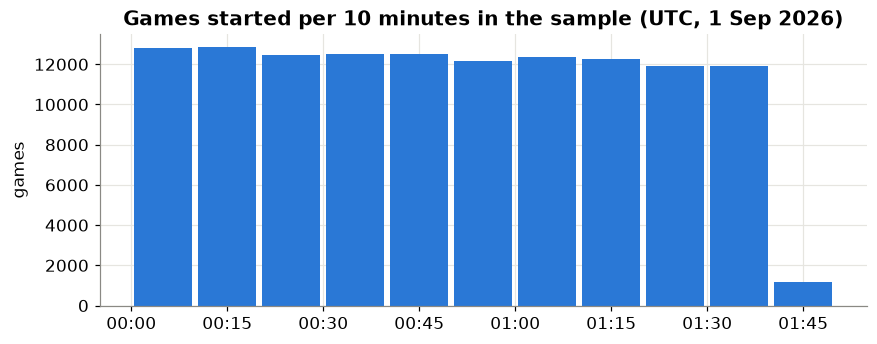

[1] games: 124913
[1] moves: 8302882
[1] quarantined records: 1
[1] first game started (UTC): 2026-09-01 00:00:00
[1] last game started (UTC): 2026-09-01 01:40:59
[1] time span (minutes): 101


In [2]:
n_games = games.count()
n_moves = moves.count()
q = quarantine.groupBy("error_stage", "error_code").count().toPandas()
display(q)  # codes only; raw_excerpt is never shown

span = games.agg(F.date_format(F.min("started_at"), "yyyy-MM-dd HH:mm:ss").alias("first"),
                 F.date_format(F.max("started_at"), "yyyy-MM-dd HH:mm:ss").alias("last")).first()
# 10-minute bins: the sample is the start of the dump, so it spans a short window
bins = (games.groupBy(F.window("started_at", "10 minutes").start.alias("bin")).count()
        .orderBy("bin").toPandas())
bins["bin"] = bins["bin"].dt.tz_localize("UTC")  # Arrow gives tz-naive UTC values (CLAUDE.md)
minutes = (games.agg(((F.max("started_at").cast("long") - F.min("started_at").cast("long")) / 60).alias("m"))
           .first()["m"])

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(bins["bin"] + pd.Timedelta(minutes=5), bins["count"], width=pd.Timedelta(minutes=9), color=SINGLE)
ax.set_title("Games started per 10 minutes in the sample (UTC, 1 Sep 2026)")
ax.set_ylabel("games")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz="UTC"))
save(fig, "01_games_over_time.png")
plt.show()

note("1", "games", n_games)
note("1", "moves", n_moves)
note("1", "quarantined records", int(q["count"].sum()))
note("1", "first game started (UTC)", span["first"])
note("1", "last game started (UTC)", span["last"])
note("1", "time span (minutes)", round(minutes))

## 2. Games per time class

**Question:** which time controls dominate the sample?
**How:** count games by `time_class` (derived from `TimeControl`, data dictionary §6).
**Check:** must equal `example_02_games_by_time_class.csv` exactly.

,games,avg_plies,share_pct
time_class,,,
ultrabullet,1122,57.9,0.90
bullet,44479,65.1,35.61
blitz,57747,68.6,46.23
rapid,20824,64.1,16.67
classical,640,65.3,0.51
correspondence,101,40.8,0.08


saved docs/figures/02_games_per_time_class.png


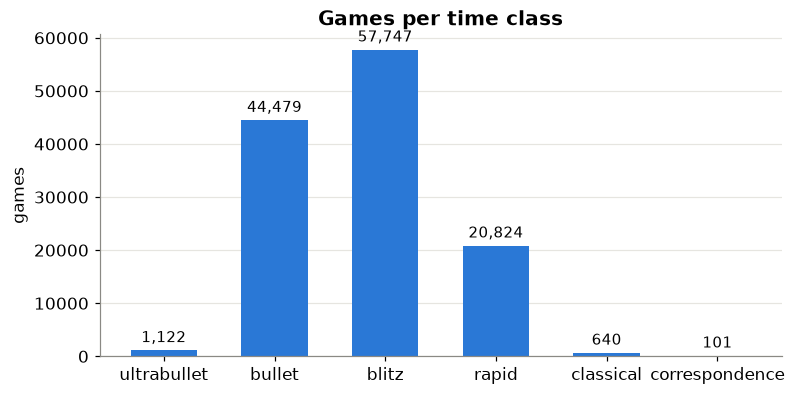

[2] games ultrabullet: 1122 (0.9%)
[2] games bullet: 44479 (35.61%)
[2] games blitz: 57747 (46.23%)
[2] games rapid: 20824 (16.67%)
[2] games classical: 640 (0.51%)
[2] games correspondence: 101 (0.08%)


In [3]:
by_class = (games.groupBy("time_class")
            .agg(F.count("*").alias("games"),
                 F.round(F.avg("n_plies"), 1).alias("avg_plies"))
            .toPandas().set_index("time_class").reindex(TIME_CLASSES))
by_class["share_pct"] = (100 * by_class["games"] / by_class["games"].sum()).round(2)
display(by_class)

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(by_class.index, by_class["games"], color=SINGLE, width=0.6)
ax.bar_label(bars, labels=[f"{v:,}" for v in by_class["games"]], padding=3, fontsize=10)
ax.set_title("Games per time class")
ax.set_ylabel("games")
ax.grid(axis="x", visible=False)
save(fig, "02_games_per_time_class.png")
plt.show()

for tc, row in by_class.iterrows():
    note("2", f"games {tc}", f"{int(row.games)} ({row.share_pct}%)")

## 3. Elo distribution

**Question:** what playing strength does the sample cover?
**How:** each game has two pre-game ratings, so each side counts once (`white_elo` and `black_elo`).
Ratings are separate per time control on Lichess, so the distribution is shown per time class
(the four main ones; ultrabullet and correspondence are in the table).
**Check:** no rating outside 400-3500 (validation: 0 games).

,ratings,min,median,mean,max
time_class,,,,,
ultrabullet,2244,697,1766.0,1734.0,2616
bullet,88958,400,1796.0,1777.0,3108
blitz,115494,400,1634.0,1612.0,3055
rapid,41648,400,1466.0,1445.0,3035
classical,1280,707,1571.0,1561.0,2902
correspondence,202,816,1664.0,1703.0,2615


saved docs/figures/03_elo_distribution.png


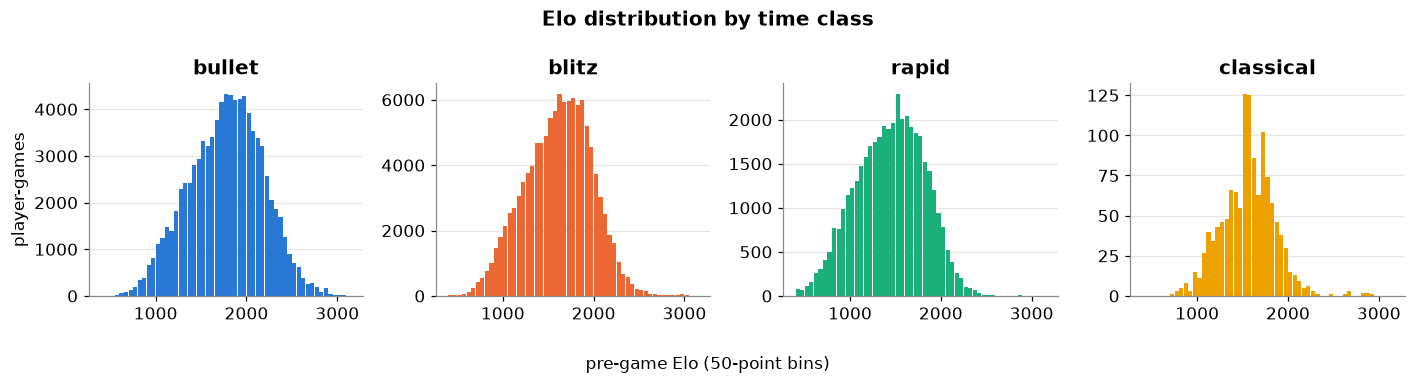

[3] ratings outside 400-3500: 0
[3] Elo ultrabullet median / min / max: 1766 / 697 / 2616
[3] Elo bullet median / min / max: 1796 / 400 / 3108
[3] Elo blitz median / min / max: 1634 / 400 / 3055
[3] Elo rapid median / min / max: 1466 / 400 / 3035
[3] Elo classical median / min / max: 1571 / 707 / 2902
[3] Elo correspondence median / min / max: 1664 / 816 / 2615


In [4]:
sides = (games.select("time_class", F.col("white_elo").alias("elo"))
         .unionByName(games.select("time_class", F.col("black_elo").alias("elo"))))
elo_stats = (sides.groupBy("time_class")
             .agg(F.count("*").alias("ratings"), F.min("elo").alias("min"),
                  F.expr("percentile(elo, 0.5)").alias("median"),
                  F.round(F.avg("elo"), 0).alias("mean"), F.max("elo").alias("max"))
             .toPandas().set_index("time_class").reindex(TIME_CLASSES))
display(elo_stats)

hist = (sides.withColumn("bin", (F.floor(F.col("elo") / 50) * 50).cast("int"))
        .groupBy("time_class", "bin").count().toPandas())
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharex=True)
for ax, tc in zip(axes, ["bullet", "blitz", "rapid", "classical"]):
    h = hist[hist.time_class == tc].sort_values("bin")
    ax.bar(h["bin"] + 25, h["count"], width=46, color=CLASS_COLOR[tc])
    ax.set_title(tc)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("player-games")
fig.supxlabel("pre-game Elo (50-point bins)", fontsize=11)
fig.suptitle("Elo distribution by time class", fontweight="bold")
fig.tight_layout()
save(fig, "03_elo_distribution.png")
plt.show()

note("3", "ratings outside 400-3500", int(sides.where((F.col("elo") < 400) | (F.col("elo") > 3500)).count()))
for tc, row in elo_stats.dropna().iterrows():
    note("3", f"Elo {tc} median / min / max", f"{row['median']:.0f} / {int(row['min'])} / {int(row['max'])}")

## 4. Clock and engine-evaluation availability

**Question:** which behavioural signals can Part 2 rely on?
**How:** share of games with `has_clock` (every move carries `%clk`) and `has_eval` (at least one move carries
`%eval`), per time class and overall.
**Check:** 124,516 games with clocks; 13,003 games (10.41%) with evals; eval % per class as in `example_02`.

,games,with_clock,with_eval,pct_clock,pct_eval
time_class,,,,,
ultrabullet,1122,1111,92,99.02,8.20
bullet,44479,44455,2556,99.95,5.75
blitz,57747,57592,5971,99.73,10.34
rapid,20824,20721,4126,99.51,19.81
classical,640,637,235,99.53,36.72
correspondence,101,0,23,0.00,22.77


saved docs/figures/04_clock_eval_availability.png


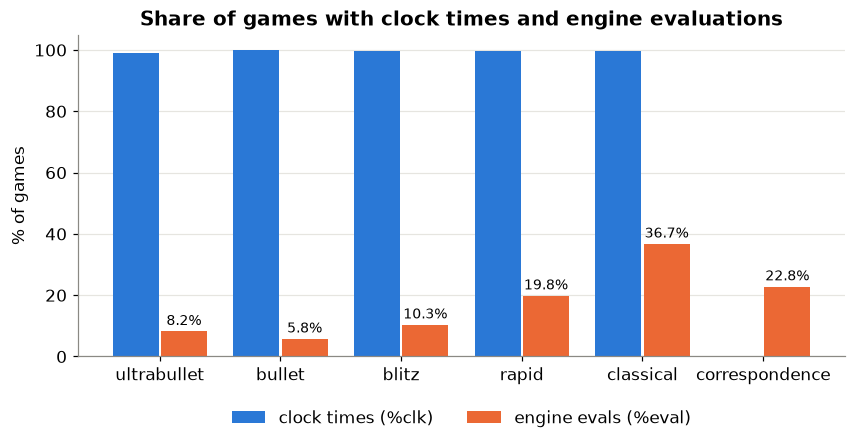

[4] games with clocks: 124516 (99.68%)
[4] games with evals: 13003 (10.41%)
[4] eval share ultrabullet: 8.2%
[4] eval share bullet: 5.75%
[4] eval share blitz: 10.34%
[4] eval share rapid: 19.81%
[4] eval share classical: 36.72%
[4] eval share correspondence: 22.77%


In [5]:
avail = (games.groupBy("time_class")
         .agg(F.count("*").alias("games"),
              F.sum(F.col("has_clock").cast("int")).alias("with_clock"),
              F.sum(F.col("has_eval").cast("int")).alias("with_eval"))
         .toPandas().set_index("time_class").reindex(TIME_CLASSES))
avail["pct_clock"] = (100 * avail["with_clock"] / avail["games"]).round(2)
avail["pct_eval"] = (100 * avail["with_eval"] / avail["games"]).round(2)
display(avail)

x = range(len(avail))
fig, ax = plt.subplots(figsize=(9, 3.8))
b1 = ax.bar([i - 0.2 for i in x], avail["pct_clock"], width=0.38, color=BLUE, label="clock times (%clk)")
b2 = ax.bar([i + 0.2 for i in x], avail["pct_eval"], width=0.38, color=ORANGE, label="engine evals (%eval)")
ax.bar_label(b2, labels=[f"{v:.1f}%" for v in avail["pct_eval"]], padding=2, fontsize=9)
ax.set_xticks(list(x), avail.index)
ax.set_ylim(0, 105)
ax.set_ylabel("% of games")
ax.set_title("Share of games with clock times and engine evaluations")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=2)
save(fig, "04_clock_eval_availability.png")
plt.show()

tot_clock, tot_eval, tot = int(avail["with_clock"].sum()), int(avail["with_eval"].sum()), int(avail["games"].sum())
note("4", "games with clocks", f"{tot_clock} ({100 * tot_clock / tot:.2f}%)")
note("4", "games with evals", f"{tot_eval} ({100 * tot_eval / tot:.2f}%)")
for tc, row in avail.iterrows():
    note("4", f"eval share {tc}", f"{row.pct_eval}%")

## 5. Move time by rating band

**Question:** how long do players of different strength take per move?
**How:** same population and rules as `core.baselines` (`sql/generate_derived.sql`): human-vs-human games
(`has_bot = false`) with clocks, moves with `move_time_s >= 0` (negative values come from lag compensation or
the opponent adding time, data dictionary §6), each move in the band of the **mover's own** pre-game Elo.
Percentiles are exact (`percentile`, same as PostgreSQL's `percentile_cont`). Cells with fewer than 30 players
are left out of the chart (report 4.6: too small to interpret) but kept in the table.
**Check:** median, p10, p90 and % under 2 s per cell must equal `example_01_median_move_time_by_band.csv`.

,time_class,band_id,band_label,n_players,n_moves,p10_s,median_s,p90_s,pct_under_2s
0,blitz,1,<800,625,37421,1.0,4.0,15.0,15.5
1,blitz,2,800-999,2056,144537,1.0,3.0,13.0,19.5
2,blitz,3,1000-1199,4006,313879,1.0,3.0,12.0,22.5
3,blitz,4,1200-1399,5850,502827,1.0,3.0,11.0,25.5
4,blitz,5,1400-1599,7207,690071,1.0,3.0,11.0,28.3
5,blitz,6,1600-1799,7182,839203,1.0,2.0,10.0,30.9
6,blitz,7,1800-1999,5671,785652,0.0,2.0,10.0,34.3
7,blitz,8,2000-2199,2885,418088,0.0,2.0,9.0,36.8
8,blitz,9,2200-2399,932,150740,0.0,2.0,9.0,40.5
9,blitz,10,2400-2599,229,33592,0.0,2.0,9.0,42.8


saved docs/figures/05_move_time_by_band.png


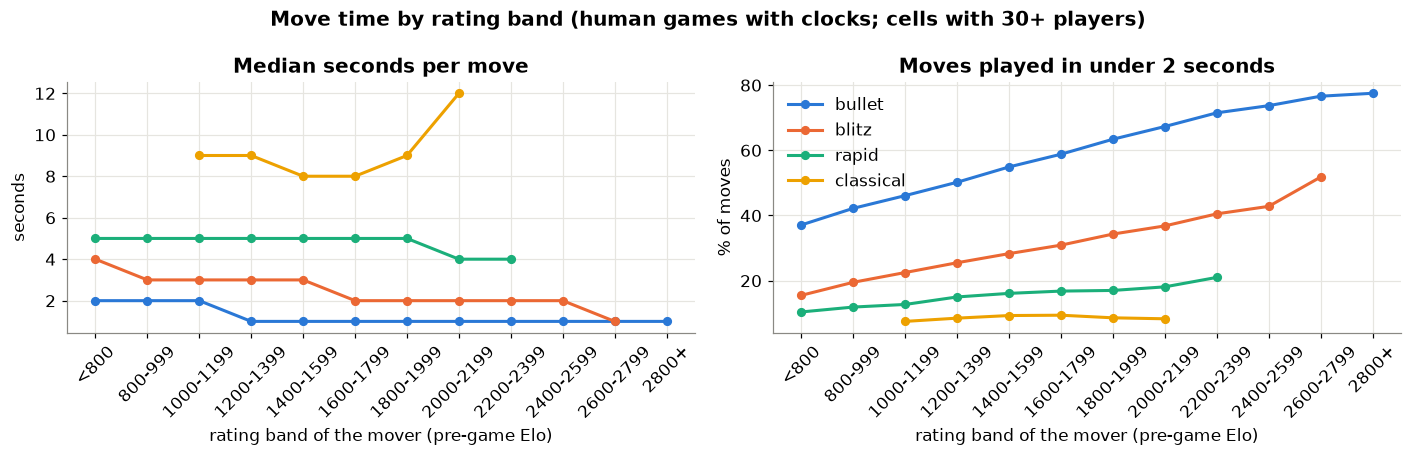

[5] moves used: 8222392
[5] band x time-class cells: 55
[5] cells with fewer than 30 players: 12
[5] bullet median s/move, <800 -> 2800+: 2 -> 1
[5] bullet % under 2 s, <800 -> 2800+: 37.1 -> 77.5
[5] blitz median s/move, <800 -> 2600-2799: 4 -> 1
[5] blitz % under 2 s, <800 -> 2600-2799: 15.5 -> 51.8
[5] rapid median s/move, <800 -> 2200-2399: 5 -> 4
[5] rapid % under 2 s, <800 -> 2200-2399: 10.4 -> 21.0
[5] classical median s/move, 1000-1199 -> 2000-2199: 9 -> 12
[5] classical % under 2 s, 1000-1199 -> 2000-2199: 7.5 -> 8.3


In [6]:
bands_df = spark.createDataFrame(BANDS, "band_id int, min_elo int, max_elo int, band_label string")
mv = (moves.alias("m")
      .join(games.select("game_id", "has_bot", "has_clock", "white_elo", "black_elo").alias("g"), "game_id")
      .where(~F.col("has_bot") & F.col("has_clock") & (F.col("move_time_s") >= 0))
      .withColumn("elo", F.when(F.col("color") == "w", F.col("white_elo")).otherwise(F.col("black_elo"))))
banded = mv.join(bands_df, (F.col("elo") >= F.col("min_elo"))
                 & (F.col("max_elo").isNull() | (F.col("elo") <= F.col("max_elo"))))
mt = (banded.groupBy("m.time_class", "band_id", "band_label")
      .agg(F.countDistinct("player_id").alias("n_players"), F.count("*").alias("n_moves"),
           F.expr("percentile(move_time_s, array(0.1, 0.5, 0.9))").alias("q"),
           F.avg((F.col("move_time_s") < 2).cast("int")).alias("share_under_2s"))
      .toPandas())
mt[["p10_s", "median_s", "p90_s"]] = pd.DataFrame(mt.pop("q").tolist(), index=mt.index)
mt["pct_under_2s"] = (100 * mt.pop("share_under_2s")).round(1)
mt = mt.sort_values(["time_class", "band_id"]).reset_index(drop=True)
display(mt)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
labels = [b[3] for b in BANDS]
for tc in ["bullet", "blitz", "rapid", "classical"]:
    d = mt[(mt.time_class == tc) & (mt.n_players >= 30)].set_index("band_label").reindex(labels)
    axes[0].plot(labels, d["median_s"], marker="o", ms=5, lw=2, color=CLASS_COLOR[tc], label=tc)
    axes[1].plot(labels, d["pct_under_2s"], marker="o", ms=5, lw=2, color=CLASS_COLOR[tc], label=tc)
axes[0].set_title("Median seconds per move")
axes[0].set_ylabel("seconds")
axes[1].set_title("Moves played in under 2 seconds")
axes[1].set_ylabel("% of moves")
for ax in axes:
    ax.set_xlabel("rating band of the mover (pre-game Elo)")
    ax.tick_params(axis="x", rotation=45)
axes[1].legend(loc="upper left")
fig.suptitle("Move time by rating band (human games with clocks; cells with 30+ players)", fontweight="bold")
fig.tight_layout()
save(fig, "05_move_time_by_band.png")
plt.show()

note("5", "moves used", int(mt["n_moves"].sum()))
note("5", "band x time-class cells", len(mt))
note("5", "cells with fewer than 30 players", int((mt.n_players < 30).sum()))
for tc in ["bullet", "blitz", "rapid", "classical"]:
    d = mt[(mt.time_class == tc) & (mt.n_players >= 30)]
    lo, hi = d.iloc[0], d.iloc[-1]
    note("5", f"{tc} median s/move, {lo.band_label} -> {hi.band_label}", f"{lo.median_s:g} -> {hi.median_s:g}")
    note("5", f"{tc} % under 2 s, {lo.band_label} -> {hi.band_label}", f"{lo.pct_under_2s} -> {hi.pct_under_2s}")

## 6. How games end

**Question:** how are games decided in each time control?
**How:** counts of the raw `Termination` header per time class (kept as-is, CLAUDE.md domain notes).
"Rules infraction" may become a weak game-level signal in Part 2.
**Check:** time-forfeit % per class must equal `example_02` (`pct_time_forfeit`).

termination,Normal,Time forfeit,Abandoned,Rules infraction,Insufficient material,Unterminated
time_class,,,,,,
ultrabullet,235,871,16,0,0,0
bullet,20083,24347,46,0,3,0
blitz,43309,14198,226,2,12,0
rapid,18358,2305,156,2,3,0
classical,577,63,0,0,0,0
correspondence,58,34,0,0,0,9


termination,Normal,Time forfeit,Abandoned,Rules infraction,Insufficient material,Unterminated
time_class,,,,,,
ultrabullet,20.94,77.63,1.43,0.00,0.00,0.00
bullet,45.15,54.74,0.10,0.00,0.01,0.00
blitz,75.00,24.59,0.39,0.00,0.02,0.00
rapid,88.16,11.07,0.75,0.01,0.01,0.00
classical,90.16,9.84,0.00,0.00,0.00,0.00
correspondence,57.43,33.66,0.00,0.00,0.00,8.91


saved docs/figures/06_termination_types.png


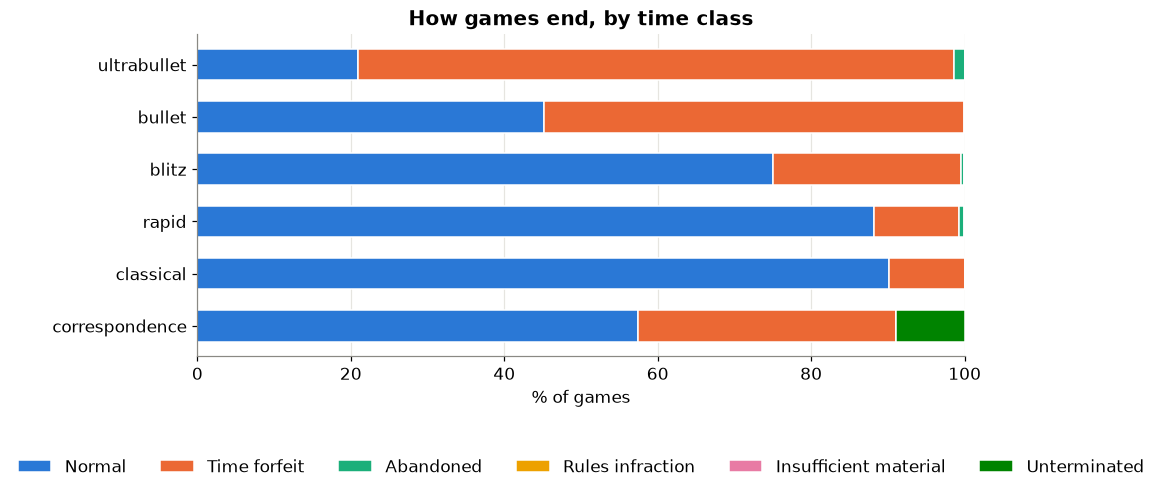

[6] termination Normal (all games): 82620 (66.14%)
[6] termination Time forfeit (all games): 41818 (33.48%)
[6] termination Abandoned (all games): 444 (0.36%)
[6] termination Rules infraction (all games): 4 (0.00%)
[6] termination Insufficient material (all games): 18 (0.01%)
[6] termination Unterminated (all games): 9 (0.01%)
[6] time forfeit ultrabullet: 77.63%
[6] time forfeit bullet: 54.74%
[6] time forfeit blitz: 24.59%
[6] time forfeit rapid: 11.07%
[6] time forfeit classical: 9.84%
[6] time forfeit correspondence: 33.66%


In [7]:
term = (games.groupBy("time_class", "termination").count().toPandas()
        .pivot(index="time_class", columns="termination", values="count").fillna(0).astype(int)
        .reindex(TIME_CLASSES))
order = [c for c in ["Normal", "Time forfeit", "Abandoned", "Rules infraction"] if c in term.columns]
order += [c for c in term.columns if c not in order]
term = term[order]
term_pct = (100 * term.div(term.sum(axis=1), axis=0)).round(2)
display(term)
display(term_pct)

colors = [BLUE, ORANGE, AQUA, YELLOW, "#e87ba4", "#008300"][:len(order)]
fig, ax = plt.subplots(figsize=(9, 3.8))
left = pd.Series(0.0, index=term_pct.index)
for col, c in zip(order, colors):
    ax.barh(term_pct.index, term_pct[col], left=left, color=c, label=col, height=0.6,
            edgecolor="white", linewidth=1)
    left += term_pct[col]
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% of games")
ax.set_title("How games end, by time class")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.42), ncols=len(order))
save(fig, "06_termination_types.png")
plt.show()

totals = term.sum()
for col in order:
    note("6", f"termination {col} (all games)", f"{int(totals[col])} ({100 * totals[col] / totals.sum():.2f}%)")
for tc in TIME_CLASSES:
    note("6", f"time forfeit {tc}", f"{term_pct.loc[tc, 'Time forfeit']}%")

## 7. BOT games

**Question:** how many games involve a BOT account?
**How:** games with `has_bot` (either side has the title `BOT`). They are kept and flagged, and left out of the
human baselines (section 5).
**Check:** 715 games (0.57%); % per class as in `example_02` (`pct_with_bot`).

,games,bot_games,pct_bot
time_class,,,
ultrabullet,1122,0,0.00
bullet,44479,179,0.40
blitz,57747,398,0.69
rapid,20824,120,0.58
classical,640,18,2.81
correspondence,101,0,0.00


saved docs/figures/07_bot_games.png


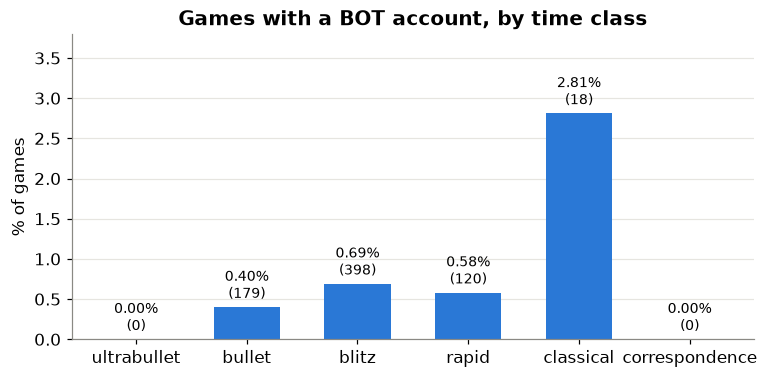

[7] games with a BOT: 715 (0.57%)


In [8]:
bots = (games.groupBy("time_class")
        .agg(F.count("*").alias("games"), F.sum(F.col("has_bot").cast("int")).alias("bot_games"))
        .toPandas().set_index("time_class").reindex(TIME_CLASSES))
bots["pct_bot"] = (100 * bots["bot_games"] / bots["games"]).round(2)
display(bots)

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(bots.index, bots["pct_bot"], color=SINGLE, width=0.6)
ax.bar_label(bars, labels=[f"{p:.2f}%\n({n})" for p, n in zip(bots["pct_bot"], bots["bot_games"])],
             padding=3, fontsize=9)
ax.set_ylim(0, bots["pct_bot"].max() * 1.35)
ax.set_ylabel("% of games")
ax.set_title("Games with a BOT account, by time class")
ax.grid(axis="x", visible=False)
save(fig, "07_bot_games.png")
plt.show()

nb, ng = int(bots["bot_games"].sum()), int(bots["games"].sum())
note("7", "games with a BOT", f"{nb} ({100 * nb / ng:.2f}%)")

## 8. Label distribution (only once labels exist)

**Question:** how rare are flagged accounts?
**How:** counts of `label` in `data/processed/player_labels.csv` (no usernames, player_id only). Skipped
until Fede's label run has produced the file.

In [9]:
labels_csv = Path(cfg["paths"]["processed_dir"]) / "player_labels.csv"
if labels_csv.exists():
    lab = pd.read_csv(labels_csv, usecols=["label", "found"])
    counts = lab["label"].value_counts().reindex(["negative", "positive", "unknown"]).fillna(0).astype(int)
    display(counts.to_frame("players"))
    fig, ax = plt.subplots(figsize=(7, 3.4))
    bars = ax.bar(counts.index, counts.values, color=SINGLE, width=0.55)
    ax.bar_label(bars, labels=[f"{v:,}\n({100 * v / counts.sum():.2f}%)" for v in counts.values],
                 padding=3, fontsize=9)
    ax.set_ylim(0, counts.max() * 1.25)
    ax.set_ylabel("players")
    ax.set_title("Player labels")
    ax.grid(axis="x", visible=False)
    save(fig, "08_label_distribution.png")
    plt.show()
    for k, v in counts.items():
        note("8", f"label {k}", f"{v} ({100 * v / counts.sum():.2f}%)")
    note("8", "players not returned by the API", int((~lab["found"].astype(bool)).sum()))
else:
    print("No labels yet:", labels_csv.relative_to(ROOT), "does not exist; chart skipped.")

No labels yet: data/processed/player_labels.csv does not exist; chart skipped.


## 9. Cross-check against the validation results

Every number above that also appears in `docs/validation_results/` must match exactly. A mismatch means the
notebook and the validation queries disagree, and the report would contain two different numbers.

In [10]:
VR = ROOT / "docs" / "validation_results"
checks = []


def check(name, mine, theirs):
    checks.append((name, mine, theirs, "PASS" if mine == theirs else "FAIL"))


vr = pd.read_csv(VR / "validation_results.csv")
obs = lambda text: vr.loc[vr.check_name.str.contains(text, regex=False), "observed"].iloc[0]
check("games", n_games, int(obs("core.games rows")))
check("moves", n_moves, int(obs("core.moves rows")))
check("quarantine", int(q["count"].sum()), int(obs("parquet quarantine rows")))
check("games with eval %", round(100 * tot_eval / tot, 2), float(obs("percent with has_eval")))
check("games without clock %", round(100 * (tot - tot_clock) / tot, 2), float(obs("percent without clocks")))
check("games with BOT %", round(100 * nb / ng, 2), float(obs("percent with a BOT player")))
check("Elo outside 400-3500", NUMBERS[[n[1] for n in NUMBERS].index("ratings outside 400-3500")][2],
      int(obs("Elo outside 400-3500")))

ex2 = pd.read_csv(VR / "example_02_games_by_time_class.csv").set_index("time_class")
for tc in TIME_CLASSES:
    check(f"{tc}: games", int(by_class.loc[tc, "games"]), int(ex2.loc[tc, "n_games"]))
    check(f"{tc}: avg plies", float(by_class.loc[tc, "avg_plies"]), float(ex2.loc[tc, "avg_plies"]))
    check(f"{tc}: eval %", float(avail.loc[tc, "pct_eval"]), float(ex2.loc[tc, "pct_with_eval"]))
    check(f"{tc}: BOT %", float(bots.loc[tc, "pct_bot"]), float(ex2.loc[tc, "pct_with_bot"]))
    check(f"{tc}: time forfeit %", float(term_pct.loc[tc, "Time forfeit"]), float(ex2.loc[tc, "pct_time_forfeit"]))

ex1 = pd.read_csv(VR / "example_01_median_move_time_by_band.csv")
m = ex1.merge(mt, on=["time_class", "band_label"], how="outer", suffixes=("_sql", "_nb"), indicator=True)
check("move-time cells (same set)", int((m._merge == "both").sum()), len(ex1))
for col in ["p10_s", "median_s", "p90_s"]:
    diff = (m[f"{col}_sql"] - m[f"{col}_nb"].round(2)).abs().max()
    check(f"move time {col}: max difference", round(float(diff), 2), 0.0)
check("move time % under 2 s: max difference",
      round(float((m["pct_moves_under_2s"] - m["pct_under_2s"]).abs().max()), 1), 0.0)
check("move time n_moves: max difference", int((m["n_moves_sql"] - m["n_moves_nb"]).abs().max()), 0)
check("move time n_players: max difference", int((m["n_players_sql"] - m["n_players_nb"]).abs().max()), 0)

result = pd.DataFrame(checks, columns=["check", "notebook", "validation_results", "status"])
display(result)
print(f"{(result.status == 'PASS').sum()} of {len(result)} checks pass")

,check,notebook,validation_results,status
0,games,124913.00,124913.00,PASS
1,moves,8302882.00,8302882.00,PASS
2,quarantine,1.00,1.00,PASS
3,games with eval %,10.41,10.41,PASS
4,games without clock %,0.32,0.32,PASS
5,games with BOT %,0.57,0.57,PASS
6,Elo outside 400-3500,0.00,0.00,PASS
7,ultrabullet: games,1122.00,1122.00,PASS
8,ultrabullet: avg plies,57.90,57.90,PASS
9,ultrabullet: eval %,8.20,8.20,PASS


44 of 44 checks pass


## 10. Save the numbers

All facts printed above, in one CSV next to the figures, so every number in report section 2.3 can be traced
to this notebook.

In [11]:
pd.DataFrame(NUMBERS, columns=["section", "metric", "value"]).to_csv(
    FIG_DIR / "dataset_analysis_numbers.csv", index=False)
print("saved", (FIG_DIR / "dataset_analysis_numbers.csv").relative_to(ROOT))
spark.stop()

saved docs/figures/dataset_analysis_numbers.csv
